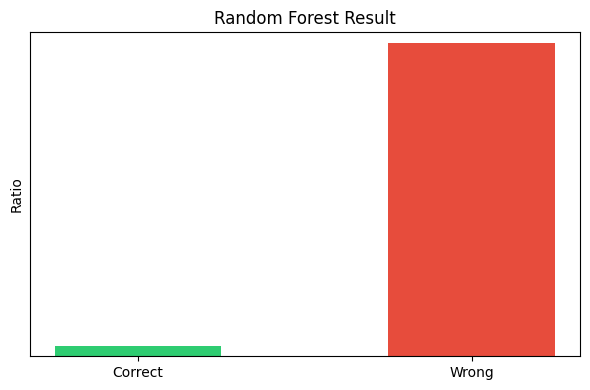

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. قراءة ملف CSV وتحديد عمود الهدف
CSV_PATH = "/kaggle/input/datasets/shahadalserhan/shatha-alserhan/diabetes_prediction_dataset.csv"
TARGET_COL = "age"

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=[TARGET_COL]).copy()

X_df = df.drop(columns=[TARGET_COL])
y_raw = df[TARGET_COL]

# معالجة الأعمدة النصية في الميزات والقيم الفارغة
X_df = pd.get_dummies(X_df, drop_first=True)
X_df = X_df.fillna(X_df.median(numeric_only=True))

# تحويل عمود الهدف إلى أرقام
le = LabelEncoder()
y = le.fit_transform(y_raw)
X = X_df.to_numpy(dtype=np.float64)

# 2. تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. تدريب Random Forest
rf = RandomForestClassifier(
    n_estimators=200, criterion="gini", random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

# 4. حساب النتيجة ورسمها فقط (بدون أرقام أو تقارير نصية)
y_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    ["Correct", "Wrong"],
    [rf_acc, 1 - rf_acc],
    color=["#2ecc71", "#e74c3c"],
    width=0.5,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Ratio")
ax.set_title("Random Forest Result")
ax.set_yticks([])  # إخفاء الأرقام من المحور الرأسي

plt.tight_layout()
plt.savefig("rf_result.png", dpi=300)
plt.show()

Adam -> Test MSE: 335.95 | R2: 0.3501


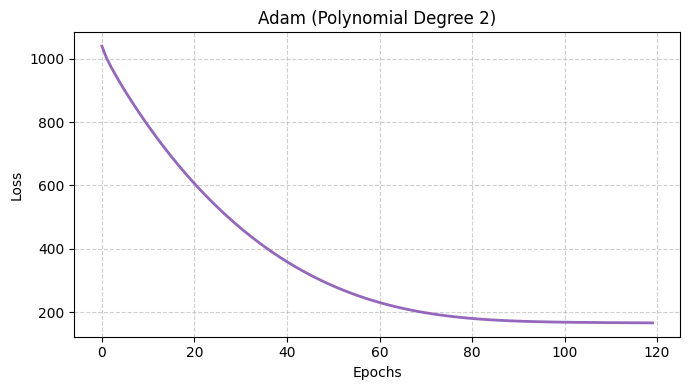

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

CSV_PATH = "/kaggle/input/datasets/shahadalserhan/shatha-alserhan/diabetes_prediction_dataset.csv"
TARGET_COL = "age"

df = pd.read_csv(CSV_PATH).dropna(subset=[TARGET_COL]).copy()
df = df.sample(n=min(5000, len(df)), random_state=42)

X_df = pd.get_dummies(df.drop(columns=[TARGET_COL]), drop_first=True)
X_df = X_df.fillna(X_df.median(numeric_only=True))
y = df[TARGET_COL].to_numpy(dtype=np.float64).reshape(-1, 1)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df.to_numpy(dtype=np.float64), y, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=2, include_bias=False)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(poly.fit_transform(X_train_raw))
X_test_scaled = scaler.transform(poly.transform(X_test_raw))

X_train = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

# تدريب Adam
lr = 0.01
beta1 = 0.9
beta2 = 0.999
eps = 1e-8
batch_size = 64
epochs = 120
n_samples = len(y_train)

np.random.seed(42)
theta = np.random.randn(X_train.shape[1], 1) * 0.01
v = np.zeros_like(theta)
s = np.zeros_like(theta)
losses = []
t = 0

for _ in range(epochs):
    indices = np.random.permutation(n_samples)
    X_shuf = X_train[indices]
    y_shuf = y_train[indices]
    for i in range(0, n_samples, batch_size):
        t += 1
        xb = X_shuf[i:i+batch_size]
        yb = y_shuf[i:i+batch_size]
        grad = (1 / len(yb)) * (xb.T @ ((xb @ theta) - yb))
        v = beta1 * v + (1 - beta1) * grad
        s = beta2 * s + (1 - beta2) * (grad ** 2)
        v_corr = v / (1 - beta1 ** t)
        s_corr = s / (1 - beta2 ** t)
        theta -= lr * v_corr / (np.sqrt(s_corr) + eps)
    losses.append((1 / (2 * n_samples)) * np.sum(((X_train @ theta) - y_train) ** 2))

y_pred = X_test @ theta
print(f"Adam -> Test MSE: {mean_squared_error(y_test, y_pred):.2f} | R2: {r2_score(y_test, y_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.plot(losses, color="#9467bd", linewidth=2)
plt.title("Adam (Polynomial Degree 2)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()